<a href="https://colab.research.google.com/github/eugeniodelrosalgp/metodos-numericos-1/blob/main/Diferencias_divididas.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Diferencias divididas

## Teoria

Suponiendo que $P_n(x)$ es el enesimo polinomio de interpolacion que concuerda con la funcion $f$ en los nodos $x_1,x_2,...,x_n$, a pesar de que este polinomio es unico por un teorema ya mencionado, existen diferentes maneras de representarlo

Las diferncias divididas de $f$ se utilizan para expresar $P_n(x)$ de ña siguiente forma
$$
\begin{aligned}
P_n(x)=a_0+a_1(x-x_0)+a_2(x-x_0)(x-x_1)+...+a_n(x-x_0)(x-x_1)...(x-x_{n-1})
\end{aligned}
$$
para $a_0,a_1,...,a_{n}$ coeficientes

la forma de determinar estos coeficientes es la siguiente, veamos que al evaluar $P_n(x)$ en $x_0$ el unico termino que no es cero es el termino $a_0$ es decir,para $a_0$ tenemos
$$
\begin{aligned}
a_0=P_n(x_0)=f(x_0)
\end{aligned}
$$
de forma similar cuando se evalua $P_n(x)$ en $x_1$ vemos que los unicos terminos restantes son $a_0+a_1(x-x_1)$ asi
$$
\begin{aligned}
P_n(x_1)=a_0+a_1(x-x_0)=f(x_0)+a_1(x-x_0)=f(x_1)
\end{aligned}
$$


siguiendo el patron vemos que la ceroesima diferencia dividida esta denotada por $f[x_i]$
$$
\begin{aligned}
f[x_i]=f(x_i)
\end{aligned}
$$
donde las diferencias restantes se calculan de manera recursivamente, donde la primera diferencia de $f$ a $x_1 $ y $x_{i+1}$ se denota como $f[x_i,x_{i+1}]$ y se define como
$$
\begin{aligned}
f[x_i,x_{i+1}]=\frac{f[x_{i+1}]-f[x_i]}{x_{i+1}-x_i}
\end{aligned}
$$
as para la k-esima diferencia dividida relativa a $x_i,x_{i+1},x_{i+2},...,x_{i+k}$tenemos
$$
\begin{aligned}
f[x_i,x_{i+1},...,x_{i+k-1},x_{i+k}]=\frac{f[x_{i+1},x_{i+2},...,x_{i+k}]]-f[x_i,x_{i+1},...,x_{i+k-1}]}{x_{i+k}-x_i}
\end{aligned}
$$
donde el proceso termina en la unica enesima diferencia dividida
$$
\begin{aligned}
f[x_0,x_{1},...,x_{n}]=\frac{f[x_{1},x_{2},...,x_{n}]]-f[x_0,x_{1},...,x_{n-1}]}{x_{n}-x_0}
\end{aligned}
$$

-0.5861074132894561*x**2 + 0.6970911144578257*x + 0.3436650122444713


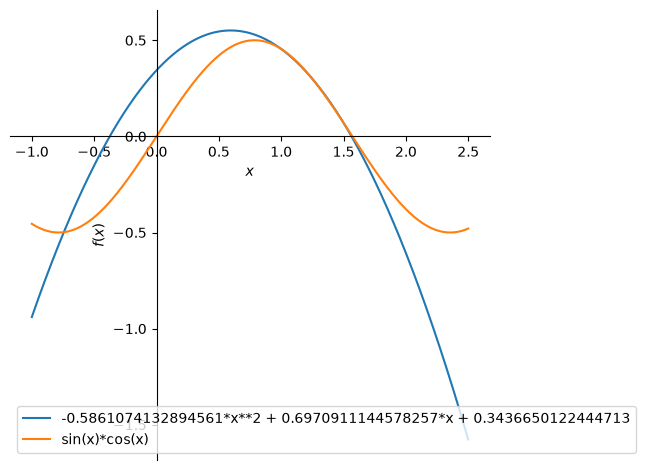

In [ ]:
import numpy as np
import sympy as sp
from sympy import *
def f_n(x):
  return np.cos(x)*np.sin(x)
#funcion para graficar en sympy
def f_s(x):
    return sp.cos(x)*sp.sin(x)
nodos=[1,1.25,1.5]
#listas para almacenar datos
coef=[]
dif1=[]
dif2=[]
n=len(nodos)
#evaluacion de las ceroesimas diferencias
for i in range(n):
  dif1.append(f_n(nodos[i]))
coef.append(dif1[0])
#evalacion recursiva de las k_esimas diferencias
for i in range(n-1):
  dif2=[]
  for j in range(len(dif1)-1):
    dif2.append((dif1[j+1]-dif1[j])/(nodos[j+i+1]-nodos[j]))
  dif1=dif2
  coef.append(dif1[0])

x=symbols("x")
P=""
#construcion del polinomio de newton
for i in range(n):
    nods=""
    for p in range(i):
        nods+=("*(x-"+str(nodos[p])+")")
    P+="+("+str(coef[i])+nods+")"
#tranformacion de forma de cadena a latex y luego simplificacion del polinomio
str_expr=P
expr=sympify(str_expr)
expr=simplify(expr)
print(expr)
s1=plotting.plot(expr,f_s(x),(x, nodos[0]-2, nodos[n-1]+1),legend=True)